# Telco Customer Churn — EDA и бизнес-инсайты

Разведочный анализ реального датасета **IBM Telco Customer Churn** (7 043 записи).
Здесь — EDA и сегментация: кто уходит и почему. Полноценное моделирование (XGBoost,
cross-validation, permutation importance) — в `churn_analysis.py`.

**Данные:** `data/telco-churn.csv` (лежит в репо, источник — [IBM/telco-customer-churn-on-icp4d](https://github.com/IBM/telco-customer-churn-on-icp4d)).

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
df = pd.read_csv("data/telco-churn.csv")
print(f"Строк: {len(df)}, колонок: {df.shape[1]}")
df.head(3)

Строк: 7043, колонок: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## Очистка

`TotalCharges` приходит строкой с 11 пустыми значениями `" "` — приводим к числу и
удаляем эти строки (те же шаги, что и в `churn_analysis.py`, чтобы выводы совпадали).

In [2]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
print(f"После очистки: {len(df)} строк (было 7043)")
print(f"Churn rate: {df['ChurnFlag'].mean():.1%}  ({df['ChurnFlag'].sum()} ушедших из {len(df)})")

После очистки: 7032 строк (было 7043)
Churn rate: 26.6%  (1869 ушедших из 7032)


## 1. Распределение целевой переменной

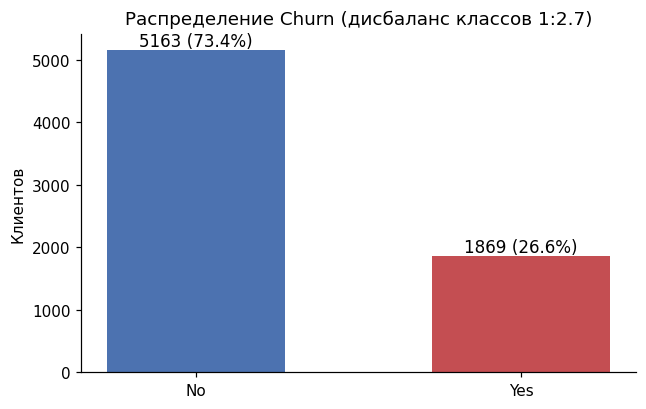

In [3]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
counts = df["Churn"].value_counts()
fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(counts.index, counts.values, color=["#4C72B0", "#C44E52"], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 60, f"{v} ({v/len(df):.1%})",
            ha="center", fontsize=11)
ax.set_title("Распределение Churn (дисбаланс классов 1:2.7)", fontsize=12)
ax.set_ylabel("Клиентов")
plt.show()

## 2. Churn по типу контракта

Главный фактор оттока по permutation importance (см. `churn_analysis.py`) —
тип контракта: помесячный контракт позволяет уйти в любой момент.

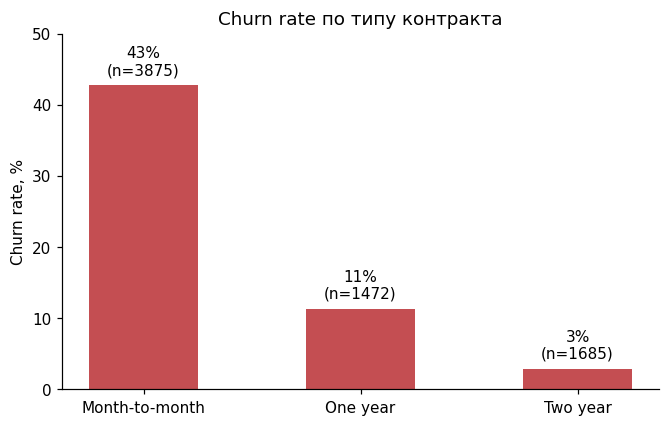

In [4]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
seg = df.groupby("Contract")["ChurnFlag"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(seg.index, seg["mean"]*100, color="#C44E52", width=0.5)
for b, (rate, n) in zip(bars, seg[["mean", "count"]].values):
    ax.text(b.get_x() + b.get_width()/2, rate*100 + 1.5,
            f"{rate:.0%}\n(n={int(n)})", ha="center", fontsize=10)
ax.set_title("Churn rate по типу контракта", fontsize=12)
ax.set_ylabel("Churn rate, %")
ax.set_ylim(0, 50)
plt.show()

## 3. Churn по стажу клиента (tenure)

Клиенты, ушедшие или оставшиеся, по-разному распределены по стажу: основная масса
ушедших — те, кто пришёл недавно.

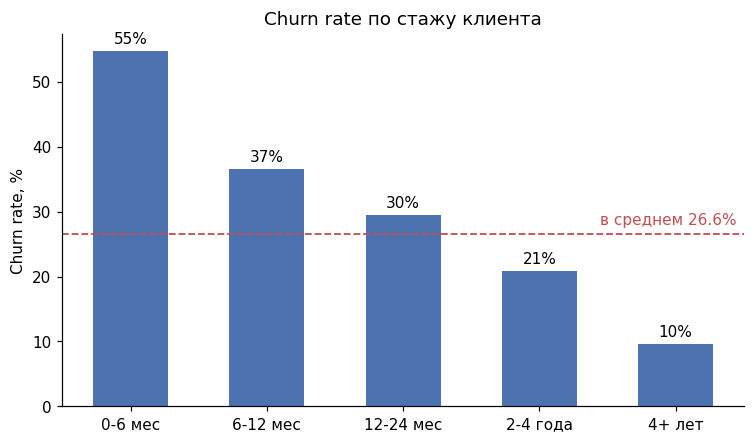

In [5]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
bins = [0, 6, 12, 24, 48, 100]
labels = ["0-6 мес", "6-12 мес", "12-24 мес", "2-4 года", "4+ лет"]
df["TenureCohort"] = pd.cut(df["tenure"], bins=bins, labels=labels, right=False)
coh = df.groupby("TenureCohort", observed=False)["ChurnFlag"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(8, 4.4))
bars = ax.bar(coh.index.astype(str), coh["mean"]*100, color="#4C72B0", width=0.55)
for b, (rate, n) in zip(bars, coh[["mean", "count"]].values):
    ax.text(b.get_x() + b.get_width()/2, rate*100 + 1.2, f"{rate:.0%}",
            ha="center", fontsize=10)
ax.axhline(df["ChurnFlag"].mean()*100, color="#C44E52", ls="--", lw=1.2)
ax.text(4.45, df["ChurnFlag"].mean()*100 + 1.5, f"в среднем {df['ChurnFlag'].mean():.1%}",
        color="#C44E52", ha="right", fontsize=10)
ax.set_title("Churn rate по стажу клиента", fontsize=12)
ax.set_ylabel("Churn rate, %")
plt.show()

## 4. MonthlyCharges и InternetService

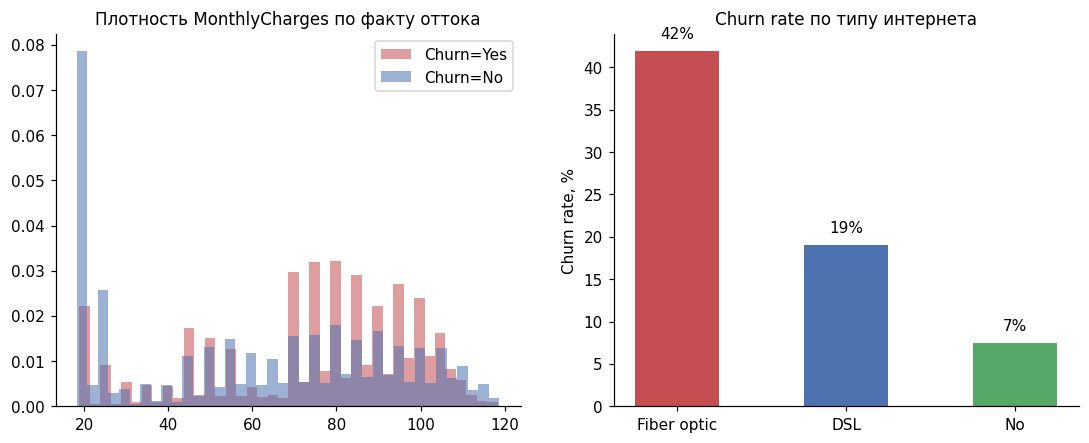

In [6]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for flag, color in [("Yes", "#C44E52"), ("No", "#4C72B0")]:
    axes[0].hist(df.loc[df["Churn"] == flag, "MonthlyCharges"], bins=40,
                 alpha=0.55, density=True, label=f"Churn={flag}", color=color)
axes[0].set_title("Плотность MonthlyCharges по факту оттока", fontsize=11)
axes[0].legend()
net = df.groupby("InternetService")["ChurnFlag"].mean().sort_values(ascending=False) * 100
axes[1].bar(net.index, net.values, color=["#C44E52", "#4C72B0", "#55A868"], width=0.5)
for i, v in enumerate(net.values):
    axes[1].text(i, v + 1.5, f"{v:.0f}%", ha="center", fontsize=10)
axes[1].set_title("Churn rate по типу интернета", fontsize=11)
axes[1].set_ylabel("Churn rate, %")
plt.show()

In [7]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
add = df.groupby(["InternetService", "OnlineSecurity"])["ChurnFlag"].mean().unstack() * 100
print("Churn rate %: интернет-сервис × наличие OnlineSecurity")
print(add.round(1).to_string())

Churn rate %: интернет-сервис × наличие OnlineSecurity
OnlineSecurity     No  No internet service   Yes
InternetService                                 
DSL              28.0                  NaN   9.5
Fiber optic      49.4                  NaN  21.8
No                NaN                  7.4   NaN


## Выводы

1. **Дисбаланс классов** — 26.6% клиентов ушло (1869 из 7032). Поэтому в `churn_analysis.py` используется `scale_pos_weight`, а основной метрикой выбран ROC-AUC (accuracy на дисбалансе обманчива).
2. **Контракт — главный фактор**: на помесячном контракте уходит 42.7% клиентов, на годовом 11.3%, на двухгодичном 2.8%. Удержание = перевод клиентов на длинные контракты.
3. **Новые клиенты — зона риска**: в когорте 0-6 мес уходит 53.3% (6-12 мес — 35.9%), а у клиентов со стажем 4+ лет — только 9.5%. Первые месяцы жизненного цикла — самое эффективное окно для retention-акций.
4. **Оптика и безопасность**: на fiber-optic уходит 41.9% против 19.0% на DSL; среди клиентов fiber **без** OnlineSecurity отток 49.4%, с защитой — 21.8%. Дорогой сервис без защиты подталкивает к уходу.
5. Дальше — моделирование: `python churn_analysis.py` (XGBoost, ROC-AUC 0.84 CV / 0.83 test).